# Panasonic vs. CMU eVTOL: input-distribution gap (current / voltage / temperature)

Paper-figure notebook. It overlays the empirical distributions of the three measured inputs -- **current, voltage, temperature** -- for the source dataset (Panasonic NCR18650PF) and the target dataset (CMU eVTOL core-seven cells), to show the size of the source-target domain gap that every transfer method in this benchmark has to bridge.

- Everything is plotted in **physical units** (A, V, degC). No scaler is fitted, so the figure shows the raw gap, not a normalised one.
- Panasonic: the seven source profiles used by the benchmark (Cycle 1-4, NN, US06, HWFET) at 25, 10, 0, -10, -20 degC, subsampled every 10 samples exactly as in `shen_2023/data.py`.
- CMU: the seven core cells (`*_dynamic_soc.parquet`, base + extension4), all rows.
- Read-only: this notebook never writes to Drive or the repo; it only saves figures/CSVs under `dataset_gap_outputs/`.
- The gap is quantified with the 1-D Wasserstein distance W₁ in each feature's own physical unit (A, V, °C), plus a table of quantiles (the table also keeps the unit-free W₁/σ).

In [8]:
from pathlib import Path
import os, subprocess, sys, tempfile
from urllib.parse import urlunsplit

from google.colab import drive, userdata
drive.mount('/content/drive')

REPO = Path('/content/battery-soc-transfer-benchmark')
REPO_URL = urlunsplit(('https', 'github.com', '/zhangcastle/battery-soc-transfer-benchmark.git', '', ''))
github_token = userdata.get('GITHUB_TOKEN')
if not github_token:
    raise RuntimeError('Add the GITHUB_TOKEN Colab Secret and enable Notebook access')
if REPO.exists() and not (REPO / '.git').exists():
    raise RuntimeError(f'Remove incomplete checkout and rerun: {REPO}')
with tempfile.TemporaryDirectory() as temp_dir:
    askpass = Path(temp_dir) / 'git-askpass.sh'
    askpass.write_text('#!/bin/sh\ncase "$1" in\n*Username*) echo "x-access-token" ;;\n*) printf "%s" "$GITHUB_TOKEN" ;;\nesac\n')
    askpass.chmod(0o700)
    git_env = os.environ.copy()
    git_env.update({'GIT_ASKPASS': str(askpass), 'GIT_TERMINAL_PROMPT': '0', 'GITHUB_TOKEN': github_token})
    command = (['git', '-C', str(REPO), 'pull', '--ff-only'] if (REPO / '.git').exists() else ['git', 'clone', '--depth', '1', REPO_URL, str(REPO)])
    result = subprocess.run(command, env=git_env, text=True, capture_output=True)
del github_token
if result.returncode:
    raise RuntimeError('Authenticated GitHub setup failed; check token permission')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(REPO)], check=True)
os.chdir(REPO)
src_path = str(REPO / 'src')
if src_path not in sys.path:
    sys.path.insert(0, src_path)
print('repo ready:', REPO)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
repo ready: /content/battery-soc-transfer-benchmark


In [9]:
"""Configuration."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from battery_benchmark.utils.config import load_yaml
from battery_benchmark.reproductions.shen_2023.data import TEMP_DIRS, _profile_paths, _load_profile

PATHS = load_yaml(REPO / 'configs/paths/colab_drive.yaml')
PANASONIC_ROOT = Path(PATHS['raw_data_root']) / 'Panasonic_18650PF'
CMU_BASE_ROOT = REPO / 'outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel'
CMU_CONDITION_ROOT = REPO / 'outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel'

# The benchmark's Panasonic source protocol (see notebook 33).
PANASONIC_TEMPERATURES = (25, 10, 0, -10, -20)
PANASONIC_PROFILES = ('Cycle_1', 'Cycle_2', 'Cycle_3', 'Cycle_4', 'NN', 'US06', 'HWFET')

# "abs": plot |current| (sign conventions can differ between datasets, so the
# magnitude is the safe cross-dataset comparison). "signed": plot as recorded.
CURRENT_MODE = 'abs'

OUTPUT_DIR = Path('dataset_gap_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DPI = 300

In [10]:
"""Load Panasonic (physical units, no scaling)."""
frames = []
for temperature in PANASONIC_TEMPERATURES:
    for profile in PANASONIC_PROFILES:
        paths = _profile_paths(PANASONIC_ROOT, temperature, profile)
        features, _ = _load_profile(paths)   # columns: Current [A], Voltage [V], Battery_Temp [degC]
        frames.append(pd.DataFrame({
            'current_a': features[:, 0], 'voltage_v': features[:, 1], 'temperature_c': features[:, 2],
            'ambient_c': temperature, 'profile': profile,
        }))
panasonic_df = pd.concat(frames, ignore_index=True)
print('Panasonic rows:', len(panasonic_df))
panasonic_df.groupby('ambient_c')[['current_a', 'voltage_v', 'temperature_c']].agg(['min', 'max'])

Panasonic rows: 251325


current_a          voltage_v          temperature_c           
                min      max       min      max           min        max
ambient_c                                                               
-20       -15.29284  0.00000   2.49562  4.18141    -20.343168  16.570168
-10       -15.28712  0.00000   2.49562  4.18270    -10.170243  16.998691
 0        -14.70977  0.00000   2.41777  4.18334      0.324454  18.272698
 10       -20.48409  9.31732   2.50141  4.20843     10.524465  23.727727
 25       -20.40978  9.87836   2.50205  4.20779     21.781981  32.770330

In [11]:
"""Load CMU eVTOL core-seven cells (physical units)."""
cmu_files = sorted(CMU_BASE_ROOT.glob('*_dynamic_soc.parquet')) + sorted(CMU_CONDITION_ROOT.glob('*_dynamic_soc.parquet'))
assert len(cmu_files) == 7, f'Expected seven CMU cell files, found {len(cmu_files)}'
parts = []
for path in cmu_files:
    raw = pd.read_parquet(path, columns=['cell_id', 'current_a', 'voltage_v', 'Temperature__C'])
    parts.append(raw.rename(columns={'Temperature__C': 'temperature_c'}))
cmu_df = pd.concat(parts, ignore_index=True).dropna(subset=['current_a', 'voltage_v', 'temperature_c'])
print('CMU rows:', len(cmu_df), '| cells:', sorted(cmu_df['cell_id'].unique()))
cmu_df.groupby('cell_id')[['current_a', 'voltage_v', 'temperature_c']].agg(['min', 'max'])

CMU rows: 2321795 | cells: ['VAH01', 'VAH11', 'VAH12', 'VAH15', 'VAH17', 'VAH27', 'VAH30']


current_a           voltage_v           temperature_c           
               min       max       min       max           min        max
cell_id                                                                  
VAH01   -21.622623 -0.066428  2.500111  4.023581     20.150858  67.949303
VAH11   -17.278006 -0.052466  2.500013  4.025710     15.933163  46.340965
VAH12   -19.382643 -0.042566  2.785274  4.027468     16.315432  60.041779
VAH15   -20.565662 -0.068319  2.627015  4.022965     21.533203  61.283398
VAH17   -21.621639 -0.064458  2.500229  4.022597     21.724371  65.909271
VAH27   -21.606074 -0.061700  2.500111  4.023542     19.510382  64.897156
VAH30   -19.308162 -0.063592  2.797650  4.030920     34.301304  68.078293

In [12]:
"""Sign-convention check: share of positive current samples per dataset
(informational; the default CURRENT_MODE='abs' makes the figure independent of it)."""
print('Panasonic  share of current > 0: %.3f' % (panasonic_df['current_a'] > 0).mean())
print('CMU        share of current > 0: %.3f' % (cmu_df['current_a'] > 0).mean())

Panasonic  share of current > 0: 0.100
CMU        share of current > 0: 0.000


In [13]:
"""Gap table: quantiles per dataset and a unit-free gap score per feature."""
FEATURES = [
    ('current_a',     '|Current| (A)' if CURRENT_MODE == 'abs' else 'Current (A)'),
    ('voltage_v',     'Voltage (V)'),
    ('temperature_c', 'Temperature (\u00b0C)'),
]
UNITS = {'current_a': 'A', 'voltage_v': 'V', 'temperature_c': '\u00b0C'}

def _feature(df, col):
    values = df[col].to_numpy(dtype=float)
    return np.abs(values) if (col == 'current_a' and CURRENT_MODE == 'abs') else values

def wasserstein_1d(a, b, n=2000):
    """1-D Wasserstein-1 via matched quantiles (no scipy dependency)."""
    q = (np.arange(n) + 0.5) / n
    return float(np.mean(np.abs(np.quantile(a, q) - np.quantile(b, q))))

rows = []
for col, label in FEATURES:
    a, b = _feature(panasonic_df, col), _feature(cmu_df, col)
    pooled_std = float(np.std(np.concatenate([a, b])))
    row = {'feature': label, 'W1': wasserstein_1d(a, b), 'W1 / pooled std': wasserstein_1d(a, b) / pooled_std}
    for name, x in (('Panasonic', a), ('CMU', b)):
        for p in (5, 50, 95):
            row[f'{name} p{p}'] = float(np.percentile(x, p))
    rows.append(row)
gap_table = pd.DataFrame(rows).set_index('feature').round(3)
gap_table.to_csv(OUTPUT_DIR / 'dataset_gap_table.csv')
gap_table

,W1,W1 / pooled std,Panasonic p5,Panasonic p50,Panasonic p95,CMU p5,CMU p50,CMU p95
feature,,,,,,,,
|Current| (A),1.938,0.453,0.000,1.028,4.996,0.595,0.612,15.556
Voltage (V),0.159,0.768,3.068,3.592,4.018,3.341,3.750,3.922
Temperature (°C),18.387,1.939,-14.787,11.625,28.130,20.145,26.014,41.452


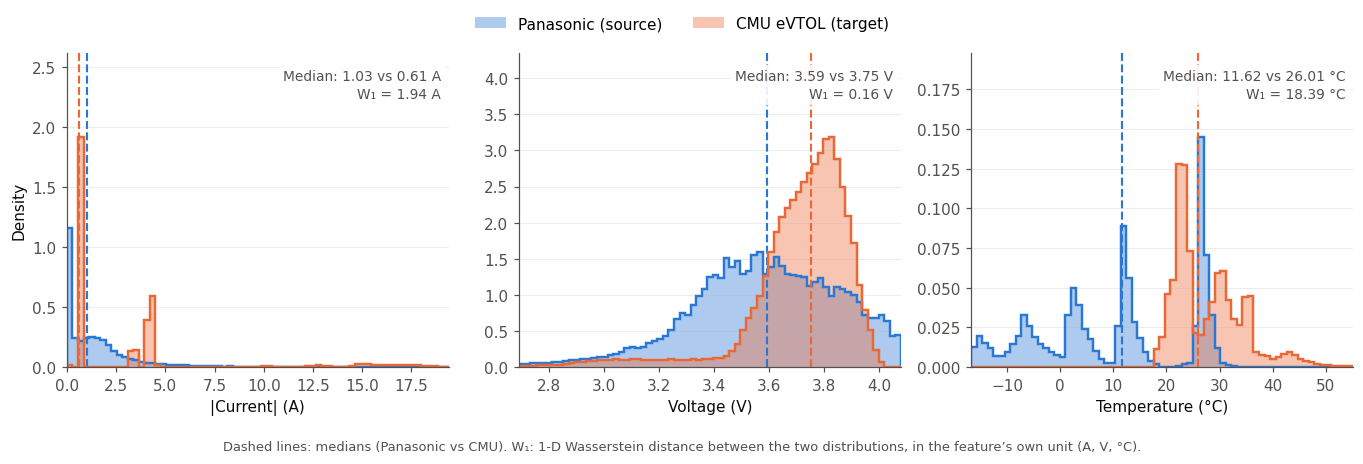

In [14]:
"""Figure: one panel per input, Panasonic vs CMU overlaid (density-normalised)."""
COLOR_PANASONIC = '#2a78d6'   # categorical slot 1
COLOR_CMU       = '#eb6834'   # categorical slot 2
INK, INK_SOFT   = '#0b0b0b', '#52514e'

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': INK_SOFT, 'axes.labelcolor': INK, 'xtick.color': INK_SOFT, 'ytick.color': INK_SOFT,
    'grid.alpha': 0.25, 'grid.linewidth': 0.6,
})

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9))
for ax, (col, label) in zip(axes, FEATURES):
    a, b = _feature(panasonic_df, col), _feature(cmu_df, col)
    lo, hi = np.percentile(np.concatenate([a, b]), [0.2, 99.8])
    bins = np.linspace(lo, hi, 70)
    for x, color, name in ((a, COLOR_PANASONIC, 'Panasonic (source)'), (b, COLOR_CMU, 'CMU eVTOL (target)')):
        ax.hist(x, bins=bins, density=True, color=color, alpha=0.38, linewidth=0, label=name)
        ax.hist(x, bins=bins, density=True, histtype='step', color=color, linewidth=1.6)
        ax.axvline(np.median(x), color=color, linewidth=1.4, linestyle='--')
    unit = UNITS[col]
    w1 = gap_table.loc[label, 'W1']
    med_a, med_b = np.median(a), np.median(b)
    ax.text(0.98, 0.95,
            f'Median: {med_a:.2f} vs {med_b:.2f} {unit}\nW\u2081 = {w1:.2f} {unit}',
            transform=ax.transAxes, ha='right', va='top', fontsize=9, color=INK_SOFT, linespacing=1.4,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='none', alpha=0.9))
    ax.set_xlabel(label)
    ax.set_ylabel('Density' if ax is axes[0] else '')
    ax.grid(True, axis='y')
    ax.set_xlim(lo, hi)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.3)   # headroom so the annotation never sits on the data

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0), fontsize=10)
fig.text(0.5, -0.02, 'Dashed lines: medians (Panasonic vs CMU). W\u2081: 1-D Wasserstein distance between the two distributions, in the feature\u2019s own unit (A, V, \u00b0C).',
         ha='center', va='top', fontsize=8.5, color=INK_SOFT)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(OUTPUT_DIR / 'dataset_gap_current_voltage_temperature.png', dpi=FIG_DPI, bbox_inches='tight')
fig.savefig(OUTPUT_DIR / 'dataset_gap_current_voltage_temperature.pdf', bbox_inches='tight')
plt.show()